Cargamos los datos del dataset limpio (docentes_enoe_sin_anomalias.csv), aplicamos One-Hot Encoding a las variables categóricas (transformamos las variables categóricas en un formato numérico), estandarizamos las caracteristicas con StandardScalar (se procesand los datos numéricos para que tengan una media de 0 y una desviación estándar de 1 lo cual es clave para KNN y Regresión Lineal) y dividimos la muestra en 80% entrenamiento y 20% prueba. 

In [8]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score,
)

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor


df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv")
df.columns = df.columns.str.lower().str.strip()
df = df.loc[:, ~df.columns.duplicated()]

col_edad = "eda" if "eda" in df.columns else "eda_x"

cols_x = ["hrsocup", col_edad, "sex", "cs_p13_1", "p3a"]
cols_totales = ["ingocup"] + cols_x

df_model = df.dropna(subset=cols_totales).copy()
df_model = df_model[(df_model["ingocup"] > 0) & (df_model["hrsocup"] > 0)]

print(f"Muestra filtrada para modelado: {len(df_model):,} docentes.")

df_encoded = pd.get_dummies(
    df_model[cols_totales], columns=["sex", "cs_p13_1", "p3a"], drop_first=True
)
df_encoded = df_encoded.loc[:, ~df_encoded.columns.duplicated()]

X = df_encoded.drop(columns=["ingocup"])
y = df_encoded["ingocup"]


X_train, X_test, y_train, y_test = train_test_split( 
    X, y, test_size=0.2, random_state=42 
)

scaler =  StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f" Conjunto de entrenamiento: {X_train.shape[0]} muestras | Conjunto de prueba: {X_test.shape[0]} muestras")

Muestra filtrada para modelado: 1,097 docentes.
 Conjunto de entrenamiento: 877 muestras | Conjunto de prueba: 220 muestras


In [12]:
# Definimos los 5 algoritmos que vamos a evaluar
modelos = {
    "Regresión Lineal (Base)": Ridge(alpha=1.0),
    "K-vecinos cercanos (KNN)": KNeighborsRegressor(
        n_neighbors=7, weights="distance"
    ),
    "Árbol de desición": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, max_depth=8, random_state=42
    ),
    "Potenciación de gradiante (perdida de Huber)": GradientBoostingRegressor(
        loss="huber", n_estimators=100, learning_rate=0.05, random_state=42
    ),
}

# Entrenamos y evaluamos cada modelo
resultados = []

for nombre, modelo in modelos.items():
    # Usar datos escalados para lineal y knn; datos originales para los basados en árboles
    if nombre in ["Regresión Lineal (Base)", "K-vecinos cercanos (KNN)"]:
        modelo.fit(X_train_scaled, y_train)
        y_pred = modelo.predict(X_test_scaled)
    else:
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    medae = mean_absolute_error(y_test, y_pred)

    resultados.append(
        {
            "Modelo": nombre,
            "R^2 Score": r2,
            "MAE ($ MXN)": mae,
            "RMSE ($ MXN)": rmse,
            "MedAE ($ MXN)": medae,
        }
    )

df_resultados = pd.DataFrame(resultados).sort_values(
    by="R^2 Score", ascending=False
)
print(" --- BENCHMARK DE MODELOS PREDICTIVOS --- ")
display(df_resultados.round(4))


 --- BENCHMARK DE MODELOS PREDICTIVOS --- 


,Modelo,R^2 Score,MAE ($ MXN),RMSE ($ MXN),MedAE ($ MXN)
4,Potenciación de gradiante (perdida de Huber),0.2304,3455.2364,4645.8207,3455.2364
0,Regresión Lineal (Base),0.2301,3493.0856,4646.7538,3493.0856
2,Árbol de desición,0.1448,3588.2163,4897.5308,3588.2163
3,Random Forest Regressor,0.1404,3624.1133,4909.9409,3624.1133
1,K-vecinos cercanos (KNN),-0.2182,4348.1290,5845.1340,4348.1290


Haremos una grafica comparativa del desempeño (R^2 y MedAE)

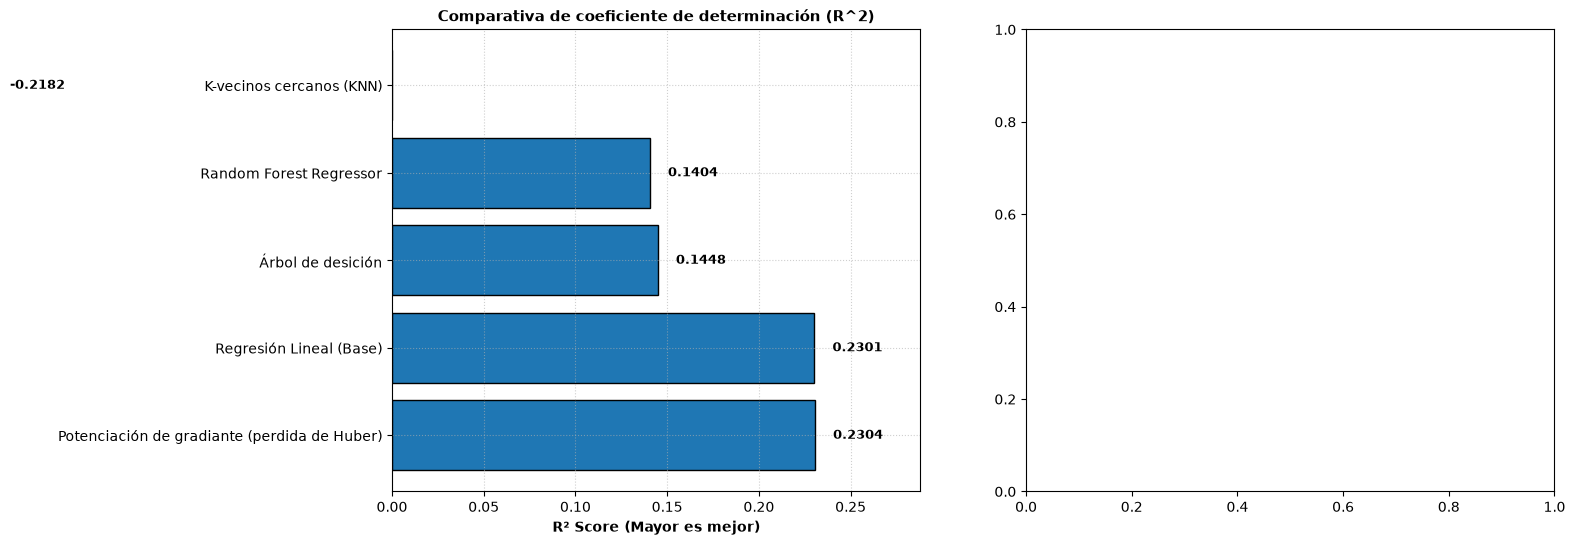

In [ ]:
os.makedirs("../outputs/figures", exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

#Grafica de R^2
bars1 = ax1.barh(
    df_resultados["Modelo"],
    df_resultados["R^2 Score"],
    color="#1f77b4",
    edgecolor="black",
)
ax1.set_title(
    "Comparativa de coeficiente de determinación (R^2)",
    fontsize=11,
    fontweight="bold",
)
ax1.set_xlabel("R² Score (Mayor es mejor)", fontweight="bold")
ax1.set_xlim(0, max(df_resultados["R^2 Score"]) * 1.25)
ax1.grid(True, linestyle=":", alpha=0.6)

for bar in bars1:
    width = bar.get_width()
    ax1.text(
        width + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.4f}",
        va="center",
        fontsize=9,
        fontweight="bold",
    )

    # Grafica de error mediano absoluto (MedAE)